> **Accuracy upgrade:** This notebook topped out around ~76% mainly because training used `train_ds_no_aug` (augmentation never applied), had no class weights, and used a thin head.
>
> Use the improved Colab notebook instead: **`train_improved_dr_model.ipynb`**
> It trains with augmentation + class weights + a stronger head + fine-tuning, then exports `efficientnetb0_dr.keras` for Render via `MODEL_URL`.


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'drive', 'processed', 'sample_data']


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/NammaRetina/processed.zip"
extract_path = "/content"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Done")

Done


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'drive', 'processed', 'sample_data']


In [ ]:
print(os.listdir("/content/processed"))
import os

print("Train:", len(os.listdir("/content/processed/train_images")))
print("Validation:", len(os.listdir("/content/processed/val_images")))
print("Test:", len(os.listdir("/content/processed/test_images")))

['test.csv', 'preprocessing_comparison.png', 'valid.csv', 'train_images', 'test_images', 'train.csv', 'val_images']
Train: 2930
Validation: 366
Test: 366


In [ ]:
DATA_DIR = "/content/processed"

TRAIN_DIR = os.path.join(DATA_DIR, "train_images")
VAL_DIR   = os.path.join(DATA_DIR, "val_images")
TEST_DIR  = os.path.join(DATA_DIR, "test_images")

TRAIN_CSV = os.path.join(DATA_DIR, "train.csv")
VAL_CSV   = os.path.join(DATA_DIR, "valid.csv")
TEST_CSV  = os.path.join(DATA_DIR, "test.csv")

In [ ]:
# ============================================================
# CELL 1: IMPORTS, GPU VERIFICATION, CONFIGURATION
# ============================================================
import os, sys, time, json, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Dense, GlobalAveragePooling2D, Dropout, BatchNormalization,
    RandomFlip, RandomRotation, RandomZoom, RandomContrast, RandomTranslation
)
from tensorflow.keras.callbacks import (
    ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, Callback
)
from sklearn.metrics import (
    cohen_kappa_score, classification_report, confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings('ignore')

# ────────────────────────────────────────────────────
# GPU & MEMORY VERIFICATION
# ────────────────────────────────────────────────────
print("=" * 65)
print("  GPU & SYSTEM VERIFICATION")
print("=" * 65)

print(f"\n  TensorFlow version:  {tf.__version__}")
print(f"  Python version:      {sys.version.split()[0]}")
print(f"  Eager execution:     {tf.executing_eagerly()}")

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    for gpu in gpus:
        print(f"  GPU detected:        {gpu.name}")
    # Print GPU name
    gpu_details = tf.config.experimental.get_device_details(gpus[0])
    if gpu_details:
        print(f"  GPU name:            {gpu_details.get('device_name', 'N/A')}")
    # Try to get memory info
    try:
        gpu_mem = tf.config.experimental.get_memory_info('GPU:0')
        print(f"  GPU memory current:  {gpu_mem['current'] / 1e9:.2f} GB")
        print(f"  GPU memory peak:     {gpu_mem['peak'] / 1e9:.2f} GB")
    except:
        print("  GPU memory:          (info not available in this TF version)")
    GPU_OK = True
else:
    print("  ⚠️  NO GPU DETECTED!")
    print("  → Go to Runtime → Change runtime type → T4 GPU → Save")
    GPU_OK = False

# ────────────────────────────────────────────────────
# CONFIGURATION (all configurable parameters)
# ────────────────────────────────────────────────────
DATA_DIR = "/content/processed"

TRAIN_DIR = os.path.join(DATA_DIR, "train_images")
VAL_DIR   = os.path.join(DATA_DIR, "val_images")
TEST_DIR  = os.path.join(DATA_DIR, "test_images")

TRAIN_CSV = os.path.join(DATA_DIR, "train.csv")
VAL_CSV   = os.path.join(DATA_DIR, "valid.csv")
TEST_CSV  = os.path.join(DATA_DIR, "test.csv")
DRIVE_MODELS = '/content/drive/MyDrive/NammaRetina/models/'

IMG_SIZE     = 224
NUM_CLASSES  = 5
AUTOTUNE     = tf.data.AUTOTUNE

# ── Batch Size (CONFIGURABLE) ──
# Recommended: 16 for T4 GPU (15 GB VRAM)
# If you get OOM errors:  lower to 8
# If training is stable:  try 32 for faster training
# Rule of thumb: smaller batch = better generalization, slower training
BATCH_SIZE = 16
# BATCH_SIZE = 8   # ← Use if you get Out Of Memory errors
# BATCH_SIZE = 32  # ← Use if GPU memory allows (faster, less regularization)

# Class info
CLASS_NAMES  = {0:'No DR', 1:'Mild', 2:'Moderate', 3:'Severe', 4:'Proliferative DR'}
CLASS_COLORS = {0:'#2ecc71', 1:'#f39c12', 2:'#e67e22', 3:'#e74c3c', 4:'#8e44ad'}

print(f"\n  Image size:          {IMG_SIZE}×{IMG_SIZE}")
print(f"  Batch size:          {BATCH_SIZE}")
print(f"  Num classes:         {NUM_CLASSES}")
print(f"  Data directory:      {DATA_DIR}")
print("=" * 65)


  GPU & SYSTEM VERIFICATION

  TensorFlow version:  2.20.0
  Python version:      3.12.13
  Eager execution:     True
  GPU detected:        /physical_device:GPU:0
  GPU name:            Tesla T4
  GPU memory current:  0.00 GB
  GPU memory peak:     0.00 GB

  Image size:          224×224
  Batch size:          16
  Num classes:         5
  Data directory:      /content/processed


In [ ]:
# ============================================================
# CELL 2: DATASET VERIFICATION
# Verifies: CSV loading, file existence, image counts
# ============================================================

# ── Load CSVs ──
train_df = pd.read_csv(TRAIN_CSV)
val_df   = pd.read_csv(VAL_CSV)
test_df  = pd.read_csv(TEST_CSV)

for df in [train_df, val_df, test_df]:
    df['filename'] = df['id_code'].astype(str) + '.png'

print("=" * 65)
print("  DATASET VERIFICATION")
print("=" * 65)

# ── Image count verification ──
EXPECTED = {'Train': 2930, 'Val': 366, 'Test': 366}
splits_info = [
    ('Train', train_df, TRAIN_DIR),
    ('Val',   val_df,   VAL_DIR),
    ('Test',  test_df,  TEST_DIR),
]

DATASET_OK = True
for name, df, img_dir in splits_info:
    # Check every file exists
    existing = sum(1 for f in df['filename'] if os.path.exists(os.path.join(img_dir, f)))
    missing  = len(df) - existing
    expected = EXPECTED[name]
    ok = (existing == expected and missing == 0)
    if not ok: DATASET_OK = False

    print(f"\n  {'✅' if ok else '❌'} {name} Images:")
    print(f"      Expected: {expected}")
    print(f"      Found:    {existing}")
    print(f"      Missing:  {missing}")
    print(f"      CSV rows: {len(df)}")

# ── Class Distribution ──
print(f"\n{'─' * 65}")
print("  CLASS DISTRIBUTION")
print(f"{'─' * 65}")

for name, df, _ in splits_info:
    dist = df['diagnosis'].value_counts().sort_index()
    print(f"\n  {name}:")
    for cls in range(NUM_CLASSES):
        count = dist.get(cls, 0)
        pct   = count / len(df) * 100
        bar   = '█' * int(pct / 2)
        print(f"    {cls} ({CLASS_NAMES[cls]:<16}): {count:>5}  ({pct:5.1f}%)  {bar}")

# ── Compute class weights ──
classes = np.sort(train_df['diagnosis'].unique())
weights = compute_class_weight('balanced', classes=classes, y=train_df['diagnosis'].values)
class_weights = {int(c): float(w) for c, w in zip(classes, weights)}

print(f"\n{'─' * 65}")
print("  COMPUTED CLASS WEIGHTS (for imbalance correction)")
print(f"{'─' * 65}")
for cls, w in class_weights.items():
    print(f"    Class {cls} ({CLASS_NAMES[cls]:<16}): weight = {w:.4f}")

if DATASET_OK:
    print(f"\n  ✅ DATASET VERIFICATION PASSED")
else:
    print(f"\n  ❌ DATASET VERIFICATION FAILED — fix missing files!")


  DATASET VERIFICATION

  ✅ Train Images:
      Expected: 2930
      Found:    2930
      Missing:  0
      CSV rows: 2930

  ✅ Val Images:
      Expected: 366
      Found:    366
      Missing:  0
      CSV rows: 366

  ✅ Test Images:
      Expected: 366
      Found:    366
      Missing:  0
      CSV rows: 366

─────────────────────────────────────────────────────────────────
  CLASS DISTRIBUTION
─────────────────────────────────────────────────────────────────

  Train:
    0 (No DR           ):  1434  ( 48.9%)  ████████████████████████
    1 (Mild            ):   300  ( 10.2%)  █████
    2 (Moderate        ):   808  ( 27.6%)  █████████████
    3 (Severe          ):   154  (  5.3%)  ██
    4 (Proliferative DR):   234  (  8.0%)  ███

  Val:
    0 (No DR           ):   172  ( 47.0%)  ███████████████████████
    1 (Mild            ):    40  ( 10.9%)  █████
    2 (Moderate        ):   104  ( 28.4%)  ██████████████
    3 (Severe          ):    22  (  6.0%)  ███
    4 (Proliferative DR): 

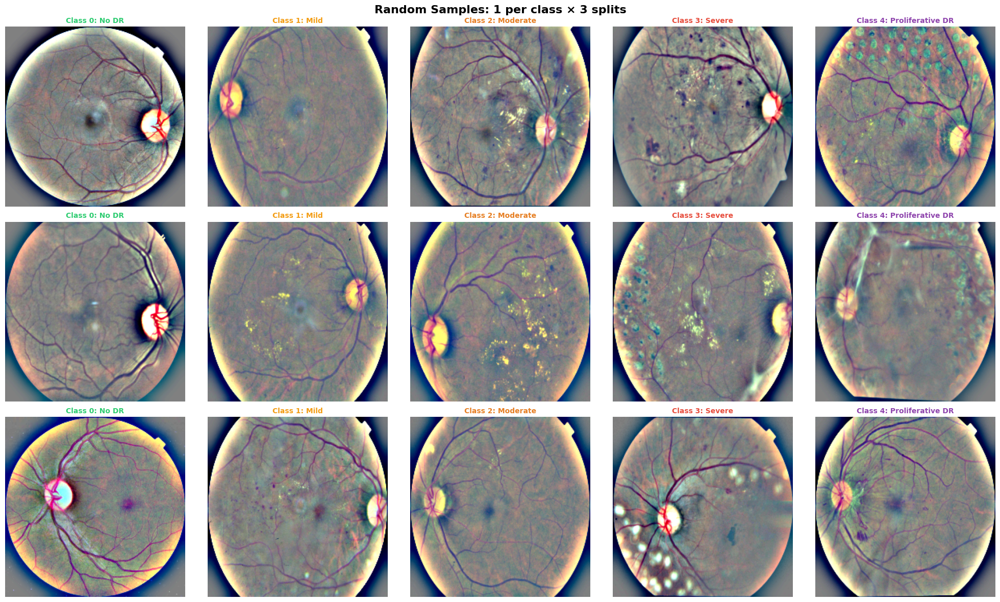

✅ Verify: images should be 224×224 Ben Graham preprocessed retinal fundus images


In [ ]:
# ============================================================
# CELL 3: DISPLAY RANDOM IMAGES FROM EACH SPLIT
# ============================================================

fig, axes = plt.subplots(3, 5, figsize=(20, 12))
fig.suptitle('Random Samples: 1 per class × 3 splits', fontsize=16, fontweight='bold')

row_labels = ['Train', 'Validation', 'Test']
for row, (name, df, img_dir) in enumerate(splits_info):
    for cls in range(NUM_CLASSES):
        class_files = df[df['diagnosis'] == cls]['filename'].values
        if len(class_files) > 0:
            chosen = np.random.choice(class_files)
            img = np.array(Image.open(os.path.join(img_dir, chosen)))
            axes[row, cls].imshow(img)
            axes[row, cls].set_title(f'Class {cls}: {CLASS_NAMES[cls]}',
                                     fontsize=10, color=CLASS_COLORS[cls], fontweight='bold')
        axes[row, cls].axis('off')
        if cls == 0:
            axes[row, cls].set_ylabel(row_labels[row], fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()
print("✅ Verify: images should be 224×224 Ben Graham preprocessed retinal fundus images")


In [ ]:
# ============================================================
# CELL 4: tf.data PIPELINE


def load_and_preprocess(file_path, label):
    """
    Load a PNG image from disk and apply EfficientNet preprocessing.

    Pipeline:  file_path → read bytes → decode PNG → resize → preprocess_input

    Ben Graham preprocessing was already applied during offline preprocessing.
    EfficientNet's preprocess_input scales pixels to [-1, 1] for ImageNet
    pretrained weights — this is a different operation than Ben Graham.
    """
    # Read raw bytes from disk
    img_bytes = tf.io.read_file(file_path)

    # Decode PNG to uint8 tensor [224, 224, 3]
    img = tf.io.decode_png(img_bytes, channels=3)

    # Resize (should already be 224×224, but safety check)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])

    # Cast to float32 for EfficientNet preprocessing
    img = tf.cast(img, tf.float32)

    # Apply EfficientNet normalization: pixels → [-1, 1]
    # This is REQUIRED even though Ben Graham was already applied
    img = img / 127.5 - 1.0

    return img, label


def create_dataset(dataframe, img_dir, shuffle=False, cache=True, augment=False):
    """
    Create a tf.data.Dataset from a DataFrame + image directory.

    Args:
        dataframe:  DataFrame with 'filename' and 'diagnosis' columns
        img_dir:    Path to the image directory
        shuffle:    Whether to shuffle (True for training only)
        cache:      Whether to cache dataset in memory (faster, uses RAM)
        augment:    Whether to apply data augmentation (training only)

    Returns:
        tf.data.Dataset yielding (image, one_hot_label) batches
    """
    # Build file paths and one-hot labels
    file_paths = [os.path.join(img_dir, f) for f in dataframe['filename'].values]
    labels     = dataframe['diagnosis'].values
    one_hot    = tf.keras.utils.to_categorical(labels, num_classes=NUM_CLASSES)

    # Create dataset from tensors
    ds = tf.data.Dataset.from_tensor_slices((file_paths, one_hot))

    # Map: load images + preprocess (parallel)
    ds = ds.map(load_and_preprocess, num_parallel_calls=AUTOTUNE)

    # Cache: store processed images in memory after first epoch
    # This avoids re-reading from disk every epoch
    if cache:
        ds = ds.cache()

    # Shuffle: randomize order (training only)
    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe), reshuffle_each_iteration=True)

    # Batch: group into batches
    ds = ds.batch(BATCH_SIZE)

    # Augment: apply augmentation AFTER batching (training only)
    if augment:
        ds = ds.map(lambda x, y: (augmentation_model(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)

    # Prefetch: prepare next batch while GPU trains on current batch
    ds = ds.prefetch(AUTOTUNE)

    return ds


# ── Create datasets ──
# Note: augmentation_model is defined in Cell 6, so we create
# train_ds WITHOUT augmentation first for verification.
# We'll recreate it WITH augmentation after Cell 6.

train_ds_no_aug = create_dataset(train_df, TRAIN_DIR, shuffle=True,  cache=True, augment=False)
val_ds          = create_dataset(val_df,   VAL_DIR,   shuffle=False, cache=True, augment=False)
test_ds         = create_dataset(test_df,  TEST_DIR,  shuffle=False, cache=True, augment=False)

print("✅ tf.data pipeline created")
print(f"   Train: {len(train_df)} images → {len(train_df)//BATCH_SIZE + 1} batches")
print(f"   Val:   {len(val_df)} images → {len(val_df)//BATCH_SIZE + 1} batches")
print(f"   Test:  {len(test_df)} images → {len(test_df)//BATCH_SIZE + 1} batches")
print(f"   Batch size:  {BATCH_SIZE}")
print(f"   Caching:     enabled (faster epochs 2+)")
print(f"   Prefetch:    AUTOTUNE")


✅ tf.data pipeline created
   Train: 2930 images → 184 batches
   Val:   366 images → 23 batches
   Test:  366 images → 23 batches
   Batch size:  16
   Caching:     enabled (faster epochs 2+)
   Prefetch:    AUTOTUNE


In [ ]:
# ============================================================
# CELL 5: tf.data PIPELINE VERIFICATION
# Verify: batch shapes, dtypes, pixel ranges, label encoding
# ============================================================

print("=" * 65)
print("  tf.data PIPELINE VERIFICATION")
print("=" * 65)

PIPELINE_OK = True

for name, ds, expected_count in [
    ('Train', train_ds_no_aug, 2930),
    ('Val',   val_ds,          366),
    ('Test',  test_ds,         366),
]:
    # Take one batch
    for batch_images, batch_labels in ds.take(1):
        img_shape  = batch_images.shape
        lbl_shape  = batch_labels.shape
        img_dtype  = batch_images.dtype
        lbl_dtype  = batch_labels.dtype
        pixel_min  = float(batch_images.numpy().min())
        pixel_max  = float(batch_images.numpy().max())
        label_sums = batch_labels.numpy().sum(axis=1)

        # Checks
        shape_ok   = (img_shape[1:] == (IMG_SIZE, IMG_SIZE, 3))
        dtype_ok   = (img_dtype == tf.float32)
        range_ok   = (pixel_min >= -1.5 and pixel_max <= 1.5)
        onehot_ok  = np.allclose(label_sums, 1.0)
        lbl_cols   = (lbl_shape[-1] == NUM_CLASSES)

        all_ok = shape_ok and dtype_ok and range_ok and onehot_ok and lbl_cols
        if not all_ok: PIPELINE_OK = False

        print(f"\n  ┌─ {name} Dataset {'─' * (50 - len(name))}")
        print(f"  │  Image batch shape:  {tuple(img_shape)}")
        print(f"  │  Label batch shape:  {tuple(lbl_shape)}")
        print(f"  │  Image dtype:        {img_dtype.name}")
        print(f"  │  Label dtype:        {lbl_dtype.name}")
        print(f"  │  Pixel min:          {pixel_min:.4f}")
        print(f"  │  Pixel max:          {pixel_max:.4f}")
        print(f"  │  Expected range:     [-1.0, 1.0]  (EfficientNet preprocess_input)")
        print(f"  │")
        print(f"  │  Shape correct:      {'✅' if shape_ok else '❌'}")
        print(f"  │  Dtype correct:      {'✅' if dtype_ok else '❌'}")
        print(f"  │  Pixel range valid:  {'✅' if range_ok else '❌'}")
        print(f"  │  Labels one-hot:     {'✅' if onehot_ok else '❌'}")
        print(f"  │  Label columns = 5:  {'✅' if lbl_cols else '❌'}")
        print(f"  └{'─' * 62}")

# ── Label Mapping Verification ──
print(f"\n{'─' * 65}")
print("  LABEL MAPPING VERIFICATION")
print(f"{'─' * 65}")
LABEL_OK = True
for cls in range(NUM_CLASSES):
    # Verify: class integer → correct class name
    sample = train_df[train_df['diagnosis'] == cls].iloc[0]
    one_hot = tf.keras.utils.to_categorical(cls, num_classes=NUM_CLASSES)
    predicted_cls = np.argmax(one_hot)
    correct = (predicted_cls == cls)
    if not correct: LABEL_OK = False
    print(f"  {'✅' if correct else '❌'} {cls} → {CLASS_NAMES[cls]:<20} one-hot: {one_hot.astype(int)}")

print(f"\n  Label mapping: {'✅ CORRECT' if LABEL_OK else '❌ INCORRECT!'}")

# ── Print normalization summary ──
print(f"\n{'─' * 65}")
print("  IMAGE NORMALIZATION SUMMARY")
print(f"{'─' * 65}")
print(f"  Step 1 (offline): Ben Graham preprocessing")
print(f"    → Enhances retinal structures: blood vessels, lesions, exudates")
print(f"    → Domain-specific medical image enhancement")
print(f"    → Already applied to your PNG files")
print(f"  Step 2 (runtime): EfficientNet preprocess_input")
print(f"    → Scales pixel values to [-1, 1] range")
print(f"    → Required by ImageNet pretrained weights")
print(f"    → Applied automatically in the tf.data pipeline")
print(f"  Both steps are COMPLEMENTARY — neither should be removed.")
print(f"\n  Pipeline verification: {'✅ PASSED' if PIPELINE_OK else '❌ FAILED'}")


  tf.data PIPELINE VERIFICATION

  ┌─ Train Dataset ─────────────────────────────────────────────
  │  Image batch shape:  (16, 224, 224, 3)
  │  Label batch shape:  (16, 5)
  │  Image dtype:        float32
  │  Label dtype:        float64
  │  Pixel min:          -1.0000
  │  Pixel max:          1.0000
  │  Expected range:     [-1.0, 1.0]  (EfficientNet preprocess_input)
  │
  │  Shape correct:      ✅
  │  Dtype correct:      ✅
  │  Pixel range valid:  ✅
  │  Labels one-hot:     ✅
  │  Label columns = 5:  ✅
  └──────────────────────────────────────────────────────────────

  ┌─ Val Dataset ───────────────────────────────────────────────
  │  Image batch shape:  (16, 224, 224, 3)
  │  Label batch shape:  (16, 5)
  │  Image dtype:        float32
  │  Label dtype:        float64
  │  Pixel min:          -1.0000
  │  Pixel max:          1.0000
  │  Expected range:     [-1.0, 1.0]  (EfficientNet preprocess_input)
  │
  │  Shape correct:      ✅
  │  Dtype correct:      ✅
  │  Pixel range va

In [ ]:

# CELL 6: DATA AUGMENTATION — Define, Verify, Visualize

# ── Build augmentation as a Keras model (runs on GPU!) ──
augmentation_model = tf.keras.Sequential([
    # Rotation: full 360° — retinal images are rotationally invariant
    RandomRotation(
        factor=1.0,         # 1.0 = ±360° (full rotation)
        fill_mode='constant',
        fill_value=0.0      # After preprocess_input, 0.0 ≈ mid-grey
    ),
    # Horizontal flip: simulates left/right eye
    RandomFlip("horizontal"),
    # Vertical flip: additional diversity
    RandomFlip("vertical"),
    # Zoom: ±10% — simulates slight focal distance changes
    RandomZoom(
        height_factor=(-0.10, 0.10),
        width_factor=(-0.10, 0.10),
        fill_mode='constant',
        fill_value=0.0
    ),
    # Translation: ±5% shift — simulates camera centering
    RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode='constant',
        fill_value=0.0
    ),
    # Contrast: ±15% — simulates exposure/lighting variation
    RandomContrast(factor=0.15),
], name='retinal_augmentation')

print("✅ Augmentation model defined (runs on GPU)")
print(f"   Layers: {[l.name for l in augmentation_model.layers]}")

# ── Now recreate train_ds WITH augmentation ──
train_ds = create_dataset(train_df, TRAIN_DIR, shuffle=True, cache=True, augment=True)
print("✅ Training dataset recreated WITH augmentation")

#verification

print(f"\n{'=' * 65}")
print("  AUGMENTATION VERIFICATION")
print(f"{'=' * 65}")

# Test: Same validation batch should be IDENTICAL across reads
print("\n  TEST 1: Validation data — should be UNCHANGED")
val_batches = []
for batch_img, batch_lbl in val_ds.take(1):
    val_batches.append(batch_img.numpy())
for batch_img, batch_lbl in val_ds.take(1):
    val_batches.append(batch_img.numpy())
VAL_UNCHANGED = np.allclose(val_batches[0], val_batches[1], atol=1e-5)
print(f"    Two reads identical: {'✅ YES — no augmentation on val' if VAL_UNCHANGED else '❌ NO — augmentation leaking!'}")

# Test: Same test batch should be IDENTICAL across reads
print("\n  TEST 2: Test data — should be UNCHANGED")
test_batches = []
for batch_img, batch_lbl in test_ds.take(1):
    test_batches.append(batch_img.numpy())
for batch_img, batch_lbl in test_ds.take(1):
    test_batches.append(batch_img.numpy())
TEST_UNCHANGED = np.allclose(test_batches[0], test_batches[1], atol=1e-5)
print(f"    Two reads identical: {'✅ YES — no augmentation on test' if TEST_UNCHANGED else '❌ NO — augmentation leaking!'}")

# Test: Training batches should DIFFER due to augmentation + shuffle
print("\n  TEST 3: Training data — should be DIFFERENT each read")
train_batches = []
for batch_img, batch_lbl in train_ds.take(1):
    train_batches.append(batch_img.numpy())
for batch_img, batch_lbl in train_ds.take(1):
    train_batches.append(batch_img.numpy())
TRAIN_AUGMENTED = not np.allclose(train_batches[0], train_batches[1], atol=1e-5)
print(f"    Two reads different: {'✅ YES — augmentation active' if TRAIN_AUGMENTED else '❌ NO — augmentation not working!'}")

AUG_OK = VAL_UNCHANGED and TEST_UNCHANGED and TRAIN_AUGMENTED
print(f"\n  Augmentation verification: {'✅ PASSED' if AUG_OK else '❌ FAILED'}")


✅ Augmentation model defined (runs on GPU)
   Layers: ['random_rotation', 'random_flip', 'random_flip_1', 'random_zoom', 'random_translation', 'random_contrast']
✅ Training dataset recreated WITH augmentation

  AUGMENTATION VERIFICATION

  TEST 1: Validation data — should be UNCHANGED
    Two reads identical: ✅ YES — no augmentation on val

  TEST 2: Test data — should be UNCHANGED
    Two reads identical: ✅ YES — no augmentation on test

  TEST 3: Training data — should be DIFFERENT each read
    Two reads different: ✅ YES — augmentation active

  Augmentation verification: ✅ PASSED


  AUGMENTATION VISUALIZATION


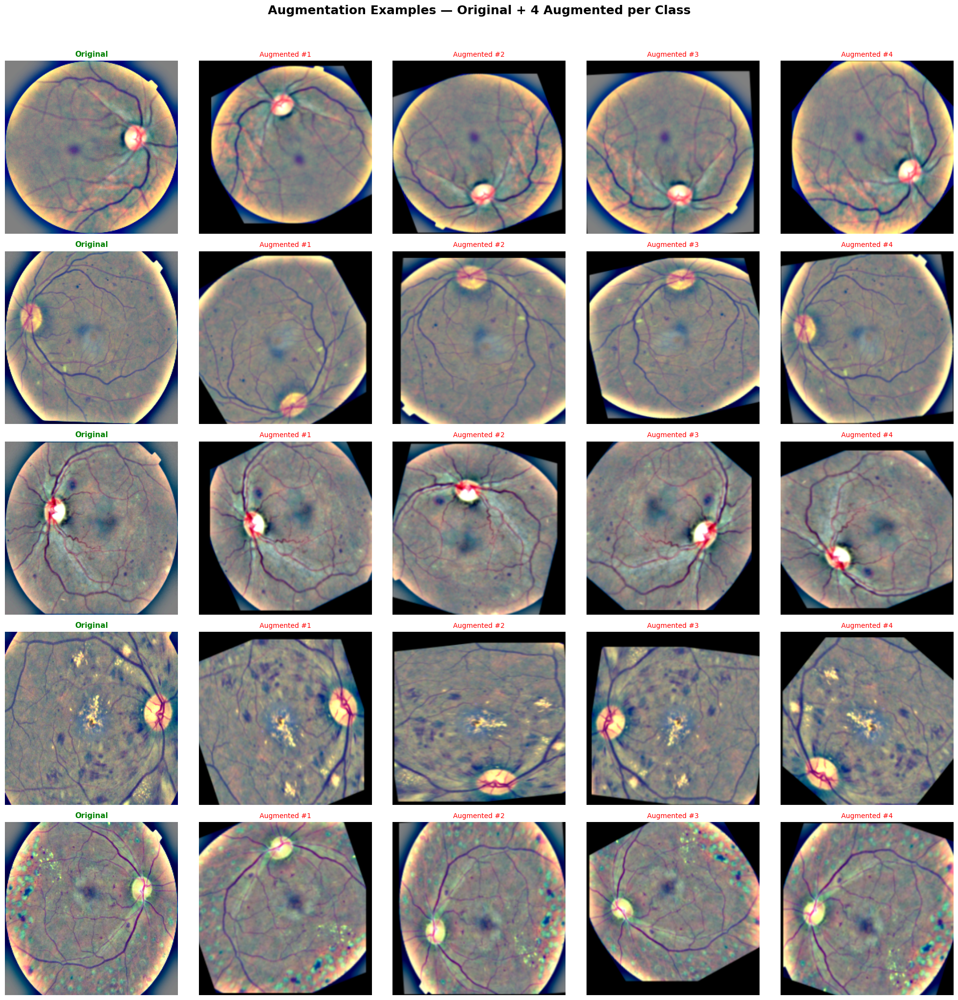


✅ Visualization completed.
Expected result:
 • Original retinal image
 • 4 realistic augmented retinal images
 • Images may be rotated, flipped, translated, zoomed
 • Blood vessels and optic disc should remain clearly visible
 • Images should NEVER become completely white or black


In [ ]:
# ============================================================
# CELL 7: AUGMENTATION VISUALIZATION
# Shows original image + 4 augmented versions for each class
# ============================================================

print("=" * 65)
print("  AUGMENTATION VISUALIZATION")
print("=" * 65)

fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(20, 20))
fig.suptitle(
    "Augmentation Examples — Original + 4 Augmented per Class",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

for cls in range(NUM_CLASSES):

    # Pick one sample image from this class
    sample_row = train_df[train_df["diagnosis"] == cls].sample(
        1,
        random_state=cls
    )

    sample_fn = sample_row["filename"].values[0]
    sample_path = os.path.join(TRAIN_DIR, sample_fn)

    # -------------------------------------------------------
    # ORIGINAL IMAGE
    # -------------------------------------------------------
    original = np.array(Image.open(sample_path))

    axes[cls, 0].imshow(original)
    axes[cls, 0].set_title(
        "Original",
        fontsize=11,
        color="green",
        fontweight="bold"
    )

    axes[cls, 0].set_ylabel(
        f"Class {cls}\n{CLASS_NAMES[cls]}",
        fontsize=12,
        color=CLASS_COLORS[cls],
        fontweight="bold"
    )

    axes[cls, 0].axis("off")

    # -------------------------------------------------------
    # LOAD IMAGE FOR AUGMENTATION
    # NOTE:
    # NO preprocess_input() here.
    # Augmentation is visualized on raw image pixels.
    # -------------------------------------------------------

    img = tf.io.read_file(sample_path)
    img = tf.io.decode_png(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = tf.cast(img, tf.float32)

    # -------------------------------------------------------
    # SHOW 4 RANDOM AUGMENTATIONS
    # -------------------------------------------------------

    for aug in range(4):

        batch = tf.expand_dims(img, axis=0)

        augmented = augmentation_model(
            batch,
            training=True
        )[0]

        augmented = augmented.numpy()

        # Clip values back to displayable range
        augmented = np.clip(
            augmented,
            0,
            255
        ).astype(np.uint8)

        axes[cls, aug + 1].imshow(augmented)

        axes[cls, aug + 1].set_title(
            f"Augmented #{aug+1}",
            fontsize=10,
            color="red"
        )

        axes[cls, aug + 1].axis("off")

plt.tight_layout()
plt.show()

print("\n✅ Visualization completed.")
print("Expected result:")
print(" • Original retinal image")
print(" • 4 realistic augmented retinal images")
print(" • Images may be rotated, flipped, translated, zoomed")
print(" • Blood vessels and optic disc should remain clearly visible")
print(" • Images should NEVER become completely white or black")

In [ ]:
# ============================================================
# CELL 8: BUILD EFFICIENTNETB0 MODEL
# Transfer Learning using ImageNet pretrained weights
# ============================================================

from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.models import Model

print("=" * 65)
print("  BUILDING EFFICIENTNETB0 MODEL")
print("=" * 65)

# ------------------------------------------------------------
# Load pretrained EfficientNetB0 (without classification head)
# ------------------------------------------------------------
base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

# Freeze the backbone for initial training
base_model.trainable = False

print("✅ EfficientNetB0 loaded with ImageNet weights")
print("✅ Base model frozen")

# ------------------------------------------------------------
# Build Classification Head
# ------------------------------------------------------------
inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = base_model(inputs, training=False)

x = GlobalAveragePooling2D(name="global_avg_pool")(x)

x = Dropout(0.30, name="dropout")(x)

outputs = Dense(
    NUM_CLASSES,
    activation="softmax",
    name="predictions"
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="Diabetic_Retinopathy_EfficientNetB0"
)

# ------------------------------------------------------------
# Model Summary
# ------------------------------------------------------------
print("\nModel Summary\n")
model.summary()

print("\n" + "=" * 65)
print("MODEL INFORMATION")
print("=" * 65)

print(f"Input Shape        : ({IMG_SIZE}, {IMG_SIZE}, 3)")
print(f"Output Classes     : {NUM_CLASSES}")
print(f"Backbone           : EfficientNetB0")
print(f"Pretrained Weights : ImageNet")
print(f"Base Frozen        : {not base_model.trainable}")
print(f"Classifier         : GAP → Dropout → Dense({NUM_CLASSES})")

  BUILDING EFFICIENTNETB0 MODEL
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ EfficientNetB0 loaded with ImageNet weights
✅ Base model frozen

Model Summary



Model: "Diabetic_Retinopathy_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,055,976 (15.47 MB)

 Trainable params: 6,405 (25.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


MODEL INFORMATION
Input Shape        : (224, 224, 3)
Output Classes     : 5
Backbone           : EfficientNetB0
Pretrained Weights : ImageNet
Base Frozen        : True
Classifier         : GAP → Dropout → Dense(5)


In [ ]:
# ============================================================
# Cell 9: Compile the Model
# ============================================================

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.metrics import CategoricalAccuracy, Precision, Recall

# Compile the model
model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=CategoricalCrossentropy(),
    metrics=[
        CategoricalAccuracy(name="accuracy"),
        Precision(name="precision"),
        Recall(name="recall")
    ]
)

print("✅ Model compiled successfully.")

✅ Model compiled successfully.


In [ ]:
# ============================================================
# Cell 10: Define Training Callbacks
# ============================================================

import os
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Directory to save trained model
MODEL_DIR = "/content/models"
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(MODEL_DIR, "efficientnetb0_best.keras")

# Early Stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Save Best Model
checkpoint = ModelCheckpoint(
    filepath=BEST_MODEL_PATH,
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

# Reduce Learning Rate on Plateau
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

# Callback List
callbacks = [
    early_stopping,
    checkpoint,
    reduce_lr
]

print("✅ Training callbacks created successfully.")
print(f"📁 Best model will be saved to: {BEST_MODEL_PATH}")

✅ Training callbacks created successfully.
📁 Best model will be saved to: /content/models/efficientnetb0_best.keras


In [ ]:
# ============================================================
# Cell 11: Train the Model
# ============================================================

EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

print("✅ Model training completed.")


Epoch 1/20
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.4554 - loss: 1.3831 - precision: 0.5036 - recall: 0.0783
Epoch 1: val_accuracy improved from None to 0.46995, saving model to /content/models/efficientnetb0_best.keras

Epoch 1: finished saving model to /content/models/efficientnetb0_best.keras
184/184 ━━━━━━━━━━━━━━━━━━━━ 76s 220ms/step - accuracy: 0.4802 - loss: 1.3306 - precision: 0.5504 - recall: 0.1491 - val_accuracy: 0.4699 - val_loss: 1.3106 - val_precision: 0.4749 - val_recall: 0.4645 - learning_rate: 1.0000e-04
Epoch 2/20
181/184 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4879 - loss: 1.2882 - precision: 0.5315 - recall: 0.3043
Epoch 2: val_accuracy did not improve from 0.46995
184/184 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.4894 - loss: 1.2856 - precision: 0.5641 - recall: 0.2792 - val_accuracy: 0.4699 - val_loss: 1.2970 - val_precision: 0.8217 - val_recall: 0.2896 - learning_rate: 1.0000e-04
Epoch 3/20
182/184 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step -

In [ ]:
# ============================================================
# Cell 12: Evaluate on the Test Dataset
# ============================================================

from tensorflow.keras.models import load_model

# Load the best saved model
best_model = load_model(BEST_MODEL_PATH)

# Evaluate on test dataset
test_loss, test_accuracy, test_precision, test_recall = best_model.evaluate(
    test_ds,
    verbose=1
)

print("\n========== Test Results ==========")
print(f"Test Loss      : {test_loss:.4f}")
print(f"Test Accuracy  : {test_accuracy:.4f}")
print(f"Test Precision : {test_precision:.4f}")
print(f"Test Recall    : {test_recall:.4f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 14s 236ms/step - accuracy: 0.5601 - loss: 1.1335 - precision: 0.9752 - recall: 0.3224

========== Test Results ==========
Test Loss      : 1.1335
Test Accuracy  : 0.5601
Test Precision : 0.9752
Test Recall    : 0.3224


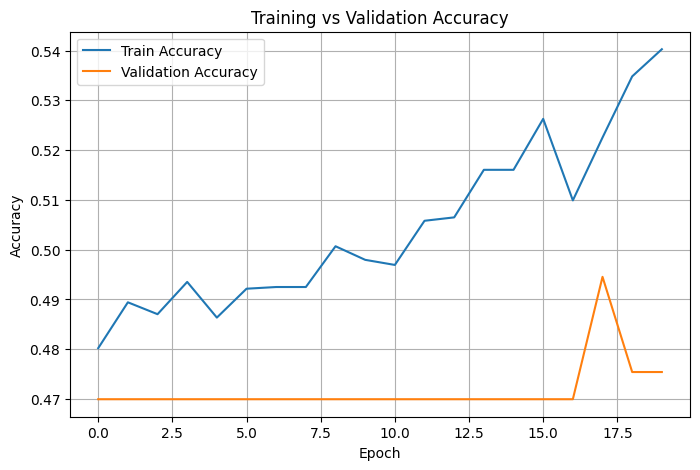

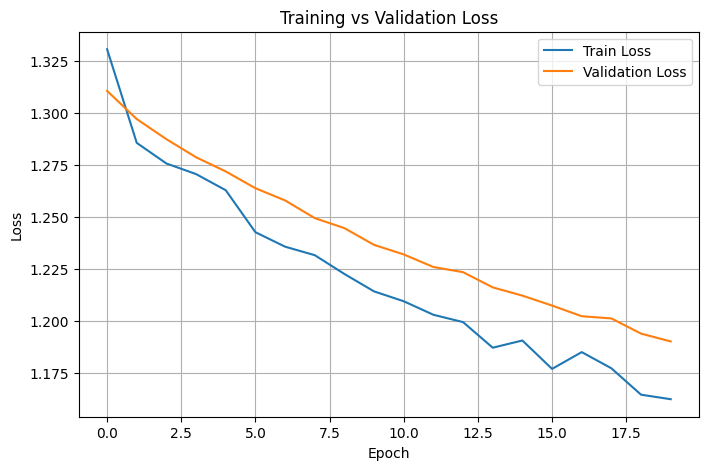

In [ ]:
# ============================================================
# Cell 13: Plot Training History
# ============================================================

import matplotlib.pyplot as plt

# Accuracy
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Loss
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

23/23 ━━━━━━━━━━━━━━━━━━━━ 16s 323ms/step
              precision    recall  f1-score   support

           0       0.60      0.97      0.74       199
           1       0.00      0.00      0.00        30
           2       0.27      0.14      0.18        87
           3       0.00      0.00      0.00        17
           4       0.00      0.00      0.00        33

    accuracy                           0.56       366
   macro avg       0.17      0.22      0.18       366
weighted avg       0.39      0.56      0.45       366



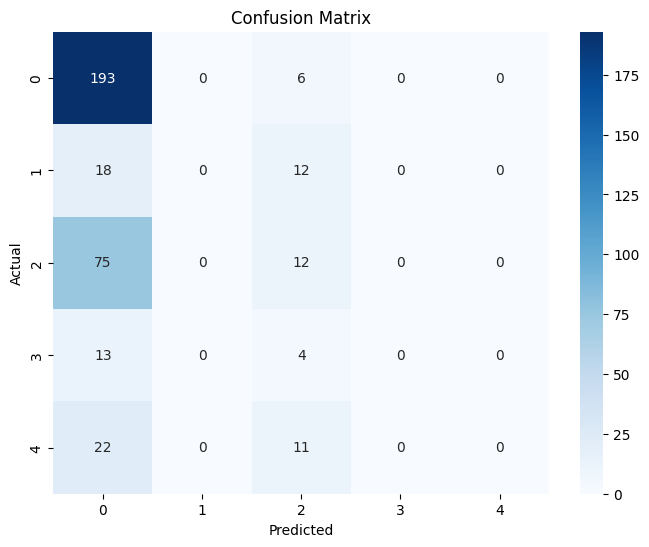

In [ ]:
# ============================================================
# Cell 14: Confusion Matrix and Classification Report
# ============================================================

import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# True labels
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_true = np.argmax(y_true, axis=1)

# Predictions
predictions = best_model.predict(test_ds)
y_pred = np.argmax(predictions, axis=1)

# Classification Report
print(classification_report(y_true, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=range(NUM_CLASSES),
    yticklabels=range(NUM_CLASSES)
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
# ============================================================
# Cell 13: Fine-Tune EfficientNetB0
# ============================================================

# Unfreeze the base model
base_model.trainable = True

# Freeze the first 70% of layers
fine_tune_at = int(len(base_model.layers) * 0.7)

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

print("Trainable layers:",
      len([l for l in base_model.layers if l.trainable]))

Trainable layers: 72


In [ ]:
# ============================================================
# Cell 14: Recompile for Fine-Tuning
# ============================================================

from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

print("Model recompiled for fine-tuning.")

Model recompiled for fine-tuning.


In [ ]:
# ============================================================
# Cell 15: Fine-Tuning Training
# ============================================================

FINE_TUNE_EPOCHS = 10

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_TUNE_EPOCHS,
    callbacks=callbacks,
    verbose=1
)

print("Fine-tuning completed.")


Epoch 1/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step - accuracy: 0.3684 - loss: 1.5370 - precision: 0.7576 - recall: 0.1298
Epoch 1: val_accuracy improved from 0.49454 to 0.60383, saving model to /content/models/efficientnetb0_best.keras

Epoch 1: finished saving model to /content/models/efficientnetb0_best.keras
184/184 ━━━━━━━━━━━━━━━━━━━━ 78s 210ms/step - accuracy: 0.4751 - loss: 1.3415 - precision: 0.8602 - recall: 0.2352 - val_accuracy: 0.6038 - val_loss: 0.9866 - val_precision: 0.8861 - val_recall: 0.3825 - learning_rate: 1.0000e-05
Epoch 2/10
183/184 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6380 - loss: 1.0399 - precision: 0.8342 - recall: 0.4117
Epoch 2: val_accuracy improved from 0.60383 to 0.64754, saving model to /content/models/efficientnetb0_best.keras

Epoch 2: finished saving model to /content/models/efficientnetb0_best.keras
184/184 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - accuracy: 0.6379 - loss: 1.0425 - precision: 0.8224 - recall: 0.4188 - val_accuracy: 0.6475 - v

In [ ]:
# ============================================================
# Cell 16: Evaluate Fine-Tuned Model
# ============================================================

best_model = load_model(BEST_MODEL_PATH)

results = best_model.evaluate(test_ds)

print(f"\nTest Accuracy : {results[1]:.4f}")
print(f"Test Precision: {results[2]:.4f}")
print(f"Test Recall   : {results[3]:.4f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 15s 295ms/step - accuracy: 0.7541 - loss: 0.7371 - precision: 0.8996 - recall: 0.5628

Test Accuracy : 0.7541
Test Precision: 0.8996
Test Recall   : 0.5628


In [ ]:
!pip install -q tf-keras-vis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.5/52.5 kB 2.7 MB/s eta 0:00:00


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf

from matplotlib import cm

from tf_keras_vis.gradcam import Gradcam
from tf_keras_vis.utils.scores import CategoricalScore
from tf_keras_vis.utils.model_modifiers import ReplaceToLinear

In [ ]:
TEST_DIR = "/content/processed/test_images"

image_path = os.path.join(
    TEST_DIR,
    test_df.iloc[0]["filename"]
)

img = tf.keras.utils.load_img(
    image_path,
    target_size=(IMG_SIZE, IMG_SIZE)
)

img_array = tf.keras.utils.img_to_array(img)

original_image = img_array.astype("uint8")

img_input = np.expand_dims(img_array, axis=0)

img_input = preprocess_input(img_input)

In [ ]:
prediction = best_model.predict(img_input, verbose=0)

predicted_class = np.argmax(prediction)

confidence = prediction[0][predicted_class]

print("Predicted Class :", predicted_class)
print("Confidence :", confidence)

Predicted Class : 3
Confidence : 0.73046577


In [ ]:
gradcam = Gradcam(
    best_model,
    model_modifier=ReplaceToLinear(),
    clone=True
)

score = CategoricalScore(predicted_class)

cam = gradcam(
    score,
    img_input,
    penultimate_layer=-1
)

heatmap = cam[0]

KeyError: "Exception encountered when calling Functional.call().\n\n\x1b[1m139845048948192\x1b[0m\n\nArguments received by Functional.call():\n  • inputs=['tf.Tensor(shape=(1, 224, 224, 3), dtype=float32)']\n  • training=False\n  • mask=['None']\n  • kwargs=<class 'inspect._empty'>"

In [ ]:
print(best_model.name)

for i, layer in enumerate(best_model.layers):
    print(i, layer.name, type(layer))

In [ ]:
base_model = best_model.layers[1]

print(base_model.name)

for i, layer in enumerate(base_model.layers[-20:]):
    print(i, layer.name, layer.__class__.__name__)